# U-Net — segmentacja obrazów (Carvana)

Ten notebook zawiera kompletną implementację sieci **U-Net** z pracy:

> O. Ronneberger, P. Fischer, T. Brox, *U-Net: Convolutional Networks for Biomedical Image Segmentation*, MICCAI 2015 (arXiv:1505.04597).

Implementacja jest możliwie bliska oryginałowi:

- wejściowy fragment **572×572**, wyjściowa maska **388×388**,
- sploty **3×3 bez paddingu** (valid) w blokach `DoubleConv`; dodatkowo up-conv 2×2 i splot 1×1 na wyjściu,
- ścieżka kurcząca i symetryczna ścieżka rozszerzająca z połączeniami pomijającymi (skip connections),
- ważona strata: rzadsza klasa i piksele przy granicach obiektów mają większy wpływ,
- strategia **overlap-tile** przy predykcji dużych obrazów.

Dane to zbiór **Carvana Image Masking Challenge**: 5088 zdjęć samochodów (RGB, 1918×1280) i binarne maski karoserii. Notebook uruchamia się z katalogu `U-Net`.

## Biblioteki i wersje

Notebook był uruchamiany na **Pythonie 3.12.6** (Windows 11, NVIDIA RTX 3050 Ti Laptop, CUDA 12.6).

| Biblioteka | Wersja | Do czego służy |
|---|---|---|
| `torch` | 2.9.1+cu126 | sieć, trening, tensory |
| `torchvision` | 0.24.1+cu126 | przycinanie map cech (`center_crop`) i augmentacja (`ElasticTransform`) |
| `numpy` | 2.5.4 | praca na obrazach i maskach |
| `Pillow` | 12.3.0 | wczytywanie JPEG/GIF |
| `matplotlib` | 3.9.3 | wizualizacje |
| `scipy` | 1.18.1 | mapa wag (`distance_transform_edt`) |
| `tqdm` | 4.67.1 | pasek postępu |
| `jupyterlab` | 4.5.0 | uruchomienie notebooka |

Przed uruchomieniem notebooka zainstaluj biblioteki w terminalu. Instalacja z GPU (CUDA 12.6):

```bash
pip install torch==2.9.1 torchvision==0.24.1 --index-url https://download.pytorch.org/whl/cu126
pip install numpy==2.5.4 Pillow==12.3.0 matplotlib==3.9.3 scipy==1.18.1 tqdm==4.67.1 jupyterlab==4.5.0
```

Wersja CPU: pomiń `--index-url` (lub użyj indeksu CPU PyTorch). Jeśli używasz innej wersji CUDA, dobierz odpowiedni indeks ze strony PyTorch.

## Konfiguracja

Najważniejsze stałe:

- `INPUT_SIZE = 572` i `OUTPUT_SIZE = 388` wynikają z architektury; dokładne wyprowadzenie jest w sekcji „Sprawdzenie architektury”.
- `CONTEXT = (572 - 388) / 2 = 92` to liczba pikseli kontekstu z każdej strony, których sieć potrzebuje, aby przewidzieć piksel na brzegu maski.
- `BATCH_SIZE = 1` i `MOMENTUM = 0.99` są zgodne z artykułem.
- `TRAIN_SAMPLES` i `VAL_SAMPLES` pozwalają ograniczyć zbiór. Domyślnie trening używa 1000 obrazów (około 20% zbioru), aby czas był rozsądny; ustaw `TRAIN_SAMPLES = None`, aby użyć wszystkich obrazów treningowych (około 90% zbioru). Walidacja używa 50 obrazów — to kompromis między czasem a wiarygodnością.

Do szybkiego sprawdzenia zmień `EPOCHS` na `1`, `TRAIN_SAMPLES` na `8`, a `VAL_SAMPLES` na `2`.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy.ndimage import distance_transform_edt
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2
from torchvision.transforms.functional import center_crop
from torchvision.tv_tensors import Image as TVImage
from torchvision.tv_tensors import Mask as TVMask
from tqdm import tqdm

BASE_DIR = Path.cwd()
if not (BASE_DIR / "data" / "imgs").exists():
    BASE_DIR = BASE_DIR / "U-Net"

DATA_DIR = BASE_DIR / "data"
IMAGES_DIR = DATA_DIR / "imgs"
MASKS_DIR = DATA_DIR / "masks"
CHECKPOINT_PATH = BASE_DIR / "unet_carvana.pth"

INPUT_SIZE = 572
OUTPUT_SIZE = 388
CONTEXT = (INPUT_SIZE - OUTPUT_SIZE) // 2
N_CLASSES = 2
EPOCHS = 5
BATCH_SIZE = 1
LEARNING_RATE = 1e-3
MOMENTUM = 0.99
TRAIN_SAMPLES = 1000
VAL_SAMPLES = 50
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Urządzenie: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Urządzenie: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


## Dane

Zbiór Carvana zawiera zdjęcia samochodów i binarne maski: `0` to tło, `1` to karoseria. Pliki są w `data/imgs` i `data/masks`. Maski mają rozszerzenie `.gif`, ale wczytujemy je jako obrazy w skali szarości.

Dane można pobrać z Kaggle: <https://www.kaggle.com/c/carvana-image-masking-challenge/data>. Oczekiwana struktura katalogów:

```text
data/
  imgs/   *.jpg
  masks/  *_mask.gif
```

Dzielimy zbiór na 90% treningu i 10% walidacji **po identyfikatorze samochodu**, a nie po pojedynczym zdjęciu. Dzięki temu walidacja zawiera inne auta niż trening i nie mierzy tylko nowych ujęć znanych samochodów. Podział jest powtarzalny dzięki `SEED = 42`.

Trening losujemy z całego zbioru, a walidację budujemy tak, aby każde auto walidacyjne miało co najmniej jedno zdjęcie: najpierw bierzemy po jednym **losowym** obrazie z każdego auta, potem po kolejnym. Dzięki temu 50 obrazów walidacyjnych obejmuje wszystkie auta walidacyjne, a widoki w obrębie auta nie są wybierane alfabetycznie.

In [2]:
assert IMAGES_DIR.exists(), f"Brak katalogu {IMAGES_DIR}"
assert MASKS_DIR.exists(), f"Brak katalogu {MASKS_DIR}"

image_ids = sorted(path.stem for path in IMAGES_DIR.glob("*.jpg"))
car_ids = sorted({image_id.split("_")[0] for image_id in image_ids})
random.Random(SEED).shuffle(car_ids)
split_index = int(0.9 * len(car_ids))
train_cars = set(car_ids[:split_index])
val_cars = set(car_ids[split_index:])
train_ids = [image_id for image_id in image_ids if image_id.split("_")[0] in train_cars]
val_ids = [image_id for image_id in image_ids if image_id.split("_")[0] in val_cars]
random.Random(SEED + 1).shuffle(train_ids)
if TRAIN_SAMPLES is not None:
    train_ids = train_ids[:TRAIN_SAMPLES]
if VAL_SAMPLES is not None:
    val_ids_by_car = {}
    for image_id in val_ids:
        val_ids_by_car.setdefault(image_id.split("_")[0], []).append(image_id)
    val_rng = random.Random(SEED + 2)
    for car_images in val_ids_by_car.values():
        val_rng.shuffle(car_images)
    balanced_val_ids = []
    max_images_per_car = max(len(car_images) for car_images in val_ids_by_car.values())
    for index in range(max_images_per_car):
        for car_images in val_ids_by_car.values():
            if index < len(car_images):
                balanced_val_ids.append(car_images[index])
    val_ids = balanced_val_ids[:VAL_SAMPLES]
assert TRAIN_SAMPLES != 0, "TRAIN_SAMPLES nie może być 0"
assert VAL_SAMPLES != 0, "VAL_SAMPLES nie może być 0"
train_car_count = len({image_id.split("_")[0] for image_id in train_ids})
val_car_count = len({image_id.split("_")[0] for image_id in val_ids})
print(f"Trening: {len(train_ids)} obrazów z {train_car_count} aut")
print(f"Walidacja: {len(val_ids)} obrazów z {val_car_count} aut")

Trening: 1000 obrazów z 284 aut
Walidacja: 50 obrazów z 32 aut


### Przykład danych

Obraz jest kolorowy, a maska jest dwuwartościowa. Po wczytaniu jako `L` maska ma wartości `0` i `255`; w datasetcie zamieniamy je na `0` i `1` przez porównanie `> 0`. Maska ma dokładnie ten sam rozmiar co zdjęcie — sieć nauczy się przewidywać maskę piksel po pikselu.

Obraz: (1918, 1280), maska: (1918, 1280)
Wartości maski: [  0 255]


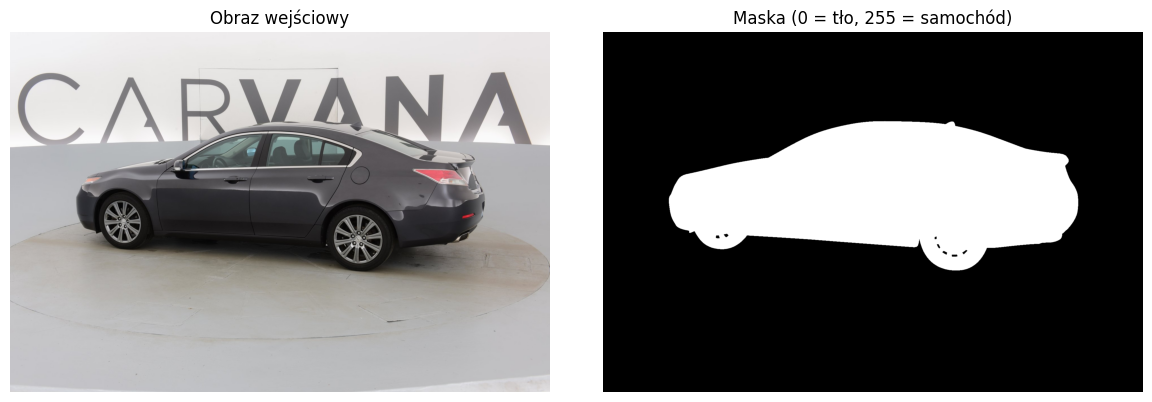

In [3]:
sample_id = train_ids[0]
sample_image = Image.open(IMAGES_DIR / f"{sample_id}.jpg").convert("RGB")
sample_mask = Image.open(MASKS_DIR / f"{sample_id}_mask.gif").convert("L")
print(f"Obraz: {sample_image.size}, maska: {sample_mask.size}")
print(f"Wartości maski: {np.unique(np.array(sample_mask))}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(sample_image)
axes[0].set_title("Obraz wejściowy")
axes[0].axis("off")
axes[1].imshow(sample_mask, cmap="gray")
axes[1].set_title("Maska (0 = tło, 255 = samochód)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## Przygotowanie fragmentów danych

Sieć nie przyjmuje całego zdjęcia 1918×1280. W każdej iteracji losujemy **region wyjściowy 388×388**, a wokół niego dokładamy **92 piksele kontekstu** z każdej strony. Otrzymujemy wejście 572×572 i maskę 388×388 — dokładnie jak w artykule.

Przy brzegach zdjęcia brakujący kontekst uzupełniamy odbiciem lustrzanym (`reflect`), tak jak w oryginalnej strategii overlap-tile. Stosujemy też augmentację inspirowaną artykułem: **deformację elastyczną** (`ElasticTransform(alpha=50, sigma=5)` — przybliżenie oryginalnych parametrów) oraz dodatkowo losowe odbicie poziome. Transformacje działają jednocześnie na obrazie i masce, więc etykiety pozostają spójne.

Dzielimy tylko przez `255`; nie stosujemy średniej i odchylenia ImageNet, bo model uczymy od zera.

Dataset zwraca obraz 572×572, maskę docelową 388×388 oraz większą maskę kontekstową 572×572. Ta ostatnia służy do policzenia mapy wag z pełnym kontekstem, a potem jest przycinana do 388×388. Walidacja odbywa się na całych obrazach, więc nie potrzebujemy drugiego zbioru kafelków.

In [4]:
class CarvanaDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids
        self.augmentation = v2.Compose([
            v2.ElasticTransform(alpha=50.0, sigma=5.0),
            v2.RandomHorizontalFlip(p=0.5),
        ])

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        image = np.array(Image.open(IMAGES_DIR / f"{image_id}.jpg").convert("RGB"))
        mask = (np.array(Image.open(MASKS_DIR / f"{image_id}_mask.gif").convert("L")) > 0).astype(np.int64)
        assert image.shape[:2] == mask.shape[:2], "Obraz i maska muszą mieć ten sam rozmiar"
        image = np.pad(image, ((CONTEXT, CONTEXT), (CONTEXT, CONTEXT), (0, 0)), mode="reflect")
        mask = np.pad(mask, ((CONTEXT, CONTEXT), (CONTEXT, CONTEXT)), mode="reflect")

        max_top = mask.shape[0] - INPUT_SIZE
        max_left = mask.shape[1] - INPUT_SIZE
        top = np.random.randint(0, max_top + 1)
        left = np.random.randint(0, max_left + 1)

        image_tile = image[top:top + INPUT_SIZE, left:left + INPUT_SIZE]
        mask_tile = mask[top:top + INPUT_SIZE, left:left + INPUT_SIZE]

        image_tile = TVImage(torch.from_numpy(image_tile.copy()).permute(2, 0, 1).contiguous())
        mask_tile = TVMask(torch.from_numpy(mask_tile.copy()))
        image_tile, mask_tile = self.augmentation(image_tile, mask_tile)

        image_tile = image_tile.float() / 255.0
        mask_context = mask_tile.long()
        mask_tile = mask_context[CONTEXT:CONTEXT + OUTPUT_SIZE, CONTEXT:CONTEXT + OUTPUT_SIZE]
        return image_tile, mask_tile, mask_context

### DataLoader

`DataLoader` łączy próbki w batche. Zgodnie z artykułem używamy batcha 1: przy dużych obrazach liczy się pamięć GPU, a nie rozmiar batcha. `num_workers = 0` jest najbezpieczniejszy w Jupyterze na Windows.

In [5]:
train_dataset = CarvanaDataset(train_ids)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
sample_images, sample_masks, sample_context_masks = next(iter(train_loader))
print(f"Batch obrazów: {sample_images.shape}")
print(f"Batch masek docelowych: {sample_masks.shape}")
print(f"Batch masek kontekstowych: {sample_context_masks.shape}")

Batch obrazów: torch.Size([1, 3, 572, 572])
Batch masek docelowych: torch.Size([1, 388, 388])
Batch masek kontekstowych: torch.Size([1, 572, 572])


## Architektura U-Net

U-Net składa się z dwóch symetrycznych części:

1. **Ścieżka kurcząca (encoder)** — powtarzamy: dwa sploty 3×3 + ReLU, potem max-pooling 2×2. Po każdym poolingu liczba kanałów się podwaja: 64 → 128 → 256 → 512 → 1024. Sploty są bez paddingu, więc obraz systematycznie się zmniejsza.
2. **Ścieżka rozszerzająca (decoder)** — najpierw splot transponowany 2×2 (`up-conv`), który podwaja rozdzielczość i zmniejsza liczbę kanałów. Potem przycinamy mapę cech z encodera do rozmiaru dekodera i **sklejamy** je (skip connection). Na końcu dwa sploty 3×3 + ReLU.
3. **Wyjście** — splot 1×1 zamienia 64 kanały na 2 klasy (tło / samochód).

Skip connections pozwalają połączyć dokładną lokalizację z encodera z kontekstem z dekodera. To dlatego U-Net dobrze radzi sobie z precyzyjnymi granicami obiektów.

W sumie są 23 warstwy splotowe: **18 splotów 3×3 + 4 up-conv 2×2 + 1 splot 1×1**, zgodnie z artykułem. Nie używamy BatchNorm — w oryginale jej nie ma. Na końcu encodera dodajemy dropout; artykuł wspomina dropout na końcu ścieżki kurczącej, ale nie podaje wartości `p`, więc `p = 0.5` to wybór autora notebooka. Inicjalizacja wag jest typu He (Kaiming), dopasowana do ReLU.

W klasie `Up` parametr `in_channels` oznacza liczbę kanałów przed up-conv. Po podziale przez 2 i sklejeniu ze skip connection do dwóch splotów trafia dokładnie `in_channels` kanałów.

In [6]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=0),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=0),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.MaxPool2d(kernel_size=2),
            DoubleConv(in_channels, out_channels),
        )

    def forward(self, x):
        return self.layers(x)


class Up(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        skip = center_crop(skip, x.shape[-2:])
        return self.conv(torch.cat([skip, x], dim=1))


class UNet(nn.Module):
    def __init__(self, in_channels=3, n_classes=2):
        super().__init__()
        self.inc = DoubleConv(in_channels, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)
        self.down4 = Down(512, 1024)
        self.dropout = nn.Dropout2d(p=0.5)
        self.up1 = Up(1024, 512)
        self.up2 = Up(512, 256)
        self.up3 = Up(256, 128)
        self.up4 = Up(128, 64)
        self.outc = nn.Conv2d(64, n_classes, kernel_size=1, padding=0)
        self._initialize_weights()

    def _initialize_weights(self):
        for module in self.modules():
            if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(module.weight, nonlinearity="relu")
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.dropout(self.down4(x4))
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.outc(x)

### Sprawdzenie architektury

Każdy splot 3×3 bez paddingu zmniejsza obraz o 2 piksele, a para splotów — o 4. Pooling zmniejsza obraz dwa razy. Dla wejścia 572×572 otrzymujemy:

| Etap | Operacja | Rozmiar |
|---|---|---|
| wejście | — | 572 |
| `inc` | 2× conv 3×3 | 568 |
| `down1` | pool + 2× conv | 280 |
| `down2` | pool + 2× conv | 136 |
| `down3` | pool + 2× conv | 64 |
| `down4` | pool + 2× conv | 28 |
| `up1` | up-conv + crop + 2× conv | 52 |
| `up2` | up-conv + crop + 2× conv | 100 |
| `up3` | up-conv + crop + 2× conv | 196 |
| `up4` | up-conv + crop + 2× conv | 388 |

Tracimy więc łącznie 184 piksele: 92 z każdej strony. Dlatego `CONTEXT = (572 - 388) / 2 = 92`. Przed każdym poolingiem rozmiar musi być parzysty — tutaj 568, 280, 136 i 64 są parzyste, więc 572 jest poprawnym rozmiarem wejścia.

Poniższy test sprawdza kształt wyjścia i liczbę parametrów.

In [7]:
model = UNet(in_channels=3, n_classes=N_CLASSES).to(DEVICE)
dummy_input = torch.zeros(1, 3, INPUT_SIZE, INPUT_SIZE, device=DEVICE)
with torch.no_grad():
    dummy_output = model(dummy_input)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
assert tuple(dummy_output.shape) == (1, N_CLASSES, OUTPUT_SIZE, OUTPUT_SIZE)
print(f"Wyjście: {tuple(dummy_output.shape)}")
print(f"Parametry: {parameter_count:,}")

Wyjście: (1, 2, 388, 388)
Parametry: 31,031,810


## Funkcja straty

W artykule sieć przewiduje dla każdego piksela rozkład prawdopodobieństwa klas (softmax), a strata to **ważona entropia krzyżowa**:

$$E = -\frac{1}{|\Omega|}\sum_{x \in \Omega} w(x) \log p_{\ell(x)}(x)$$

gdzie `w(x)` podnosi wagę pikseli rzadkiej klasy oraz pikseli blisko granic obiektów. Dzięki temu sieć nie ignoruje wąskich fragmentów i lepiej uczy się konturów. W praktyce uśredniamy stratę po pikselach, zamiast ją sumować.

Wagi klas liczymy z próbki masek: klasa rzadsza dostaje większą wagę. Człon borderowy liczymy z odległości do granicy obiektu (przybliżenie wzoru 2 z artykułu, z `w0 = 10` i `sigma = 5`). Mapę wag liczymy na większej masce kontekstowej 572×572 i przycinamy do 388×388, żeby krawędzie wycinka nie zaburzały odległości.

In [8]:
weight_sample_ids = random.Random(SEED + 3).sample(train_ids, min(100, len(train_ids)))
sample_masks = [
    np.array(Image.open(MASKS_DIR / f"{image_id}_mask.gif").convert("L")) > 0
    for image_id in weight_sample_ids
]
foreground_fraction = float(np.mean([mask.mean() for mask in sample_masks]))
class_weights = torch.tensor(
    [1.0 / (2.0 * (1.0 - foreground_fraction)), 1.0 / (2.0 * foreground_fraction)],
    dtype=torch.float32,
)
print(f"Udział samochodu: {foreground_fraction:.3f}")
print(f"Wagi klas: {class_weights.tolist()}")

Udział samochodu: 0.202
Wagi klas: [0.6269553899765015, 2.469195604324341]


### Mapa wag

Dla każdego piksela liczymy odległość do najbliższej granicy obiektu. Blisko granicy dodajemy dużą wagę (`w0 = 10`), a daleko od niej — małą. W ten sposób strata mocniej karze błędy na konturach, które są najtrudniejsze do nauczenia.

Funkcja `weighted_cross_entropy` oczekuje masek kontekstowych 572×572; docelowa maska ma 388×388, więc mapa wag jest przycinana dokładnie w tym samym miejscu co maska.

`distance_transform_edt` działa na CPU. Przy pełnym treningu ta operacja jest wąskim gardłem — można ją wtedy precomputować lub zastąpić prostszą mapą wag.

In [9]:
def make_weight_map(mask, class_weights, w0=10.0, sigma=5.0):
    foreground = mask.bool().numpy()
    if not foreground.any():
        return class_weights[mask]
    distance_to_foreground = distance_transform_edt(~foreground)
    distance_to_background = distance_transform_edt(foreground)
    border_weight = np.exp(
        -((distance_to_foreground + distance_to_background) ** 2) / (2.0 * sigma ** 2)
    )
    return class_weights[mask] + w0 * torch.from_numpy(border_weight).float()


def weighted_cross_entropy(logits, target, context_masks, class_weights, w0=10.0, sigma=5.0):
    weights = []
    for context_mask in context_masks:
        weight = make_weight_map(context_mask.cpu(), class_weights.cpu(), w0, sigma)
        weights.append(weight[CONTEXT:CONTEXT + OUTPUT_SIZE, CONTEXT:CONTEXT + OUTPUT_SIZE])
    weights = torch.stack(weights).to(logits.device)
    log_probabilities = F.log_softmax(logits, dim=1)
    target_log_probabilities = log_probabilities.gather(1, target.unsqueeze(1)).squeeze(1)
    return -(weights * target_log_probabilities).mean()

## Optymalizator

Używamy **SGD z momentum 0.99**, tak jak w artykule. Współczynnik uczenia ustawiamy na `1e-3` — to stabilna wartość dla tego modelu i pojedynczego batcha. Nie dodajemy harmonogramu ani weight decay, żeby kod pozostał prosty.

In [10]:
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM)

## Miara jakości: Dice

Dice porównuje predykcję z prawdą:

$$\text{Dice} = \frac{2|P \cap G|}{|P| + |G|}$$

Wynik 1 oznacza idealne pokrycie, 0 — brak pokrycia. Dla masek binarnych to wygodna i często używana miara.

In [11]:
def dice_score(prediction, target, epsilon=1e-6):
    prediction = prediction.bool()
    target = target.bool()
    intersection = (prediction & target).sum().item()
    denominator = prediction.sum().item() + target.sum().item()
    return (2.0 * intersection + epsilon) / (denominator + epsilon)

## Predykcja całego obrazu: overlap-tile

Sieć przewiduje tylko fragment 388×388, więc duży obraz dzielimy na kafelki. Dla każdego kafelka wyjściowego dokładamy 92 piksele kontekstu, a brakujące piksele przy krawędzi uzupełniamy odbiciem lustrzanym. Kafelki wejściowe zachodzą na siebie o 184 piksele, dzięki czemu każdy piksel wyjściowy ma pełny kontekst. Kafelki wyjściowe układają się obok siebie bez nakładania, więc każdy piksel jest liczony tylko raz. To dokładnie strategia **overlap-tile** z artykułu.

Funkcja `predict_full_image` jest używana zarówno do walidacji podczas treningu, jak i do końcowej wizualizacji.

In [12]:
@torch.no_grad()
def predict_full_image(model, image_path):
    model.eval()
    image = np.array(Image.open(image_path).convert("RGB"))
    height, width = image.shape[:2]
    output_height = int(np.ceil(height / OUTPUT_SIZE) * OUTPUT_SIZE)
    output_width = int(np.ceil(width / OUTPUT_SIZE) * OUTPUT_SIZE)
    padded = np.pad(
        image,
        (
            (CONTEXT, CONTEXT + output_height - height),
            (CONTEXT, CONTEXT + output_width - width),
            (0, 0),
        ),
        mode="reflect",
    )
    probability = np.zeros((output_height, output_width), dtype=np.float32)
    for top in range(0, output_height, OUTPUT_SIZE):
        for left in range(0, output_width, OUTPUT_SIZE):
            tile = padded[top:top + INPUT_SIZE, left:left + INPUT_SIZE]
            tile = torch.from_numpy(tile.copy()).permute(2, 0, 1).float().unsqueeze(0).to(DEVICE) / 255.0
            logits = model(tile)
            probabilities = torch.softmax(logits, dim=1)[0, 1].cpu().numpy()
            probability[top:top + OUTPUT_SIZE, left:left + OUTPUT_SIZE] = probabilities
    return probability[:height, :width]

## Trening

W każdej epoce:

1. przechodzimy przez wszystkie fragmenty treningowe,
2. liczymy stratę i aktualizujemy wagi,
3. oceniamy model na **całych obrazach walidacyjnych** metodą overlap-tile,
4. zapisujemy najlepszy model do `unet_carvana.pth`.

Dice na całym obrazie karze fałszywe alarmy w tle i obejmuje brzegi obiektu, więc jest bardziej wiarygodny niż pojedynczy wycinek. To nie jest metryka accuracy tła — true negatives nie wchodzą do licznika. Domyślnie trening używa 5 epok i 1000 obrazów, a walidacja 50 obrazów. Na pełnym zbiorze trening może potrwać kilka godzin na GPU; do szybkiego sprawdzenia ustaw `EPOCHS = 1` i `TRAIN_SAMPLES = 8`.

In [13]:
def evaluate(model, image_ids):
    model.eval()
    scores = []
    for image_id in tqdm(image_ids, desc="Walidacja", leave=False):
        probability = predict_full_image(model, IMAGES_DIR / f"{image_id}.jpg")
        ground_truth = np.array(Image.open(MASKS_DIR / f"{image_id}_mask.gif").convert("L")) > 0
        scores.append(
            dice_score(torch.from_numpy(probability > 0.5), torch.from_numpy(ground_truth))
        )
    return float(np.mean(scores)) if scores else 0.0


best_dice = -1.0
history = []
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    progress = tqdm(train_loader, desc=f"Epoka {epoch + 1}/{EPOCHS}")
    for images, masks, context_masks in progress:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        context_masks = context_masks.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = weighted_cross_entropy(logits, masks, context_masks, class_weights)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        progress.set_postfix(loss=f"{loss.item():.4f}")
    train_loss = running_loss / len(train_dataset)
    val_dice = evaluate(model, val_ids)
    history.append((train_loss, val_dice))
    print(f"Epoka {epoch + 1}: loss={train_loss:.4f}, Dice={val_dice:.4f}")
    if val_dice > best_dice:
        best_dice = val_dice
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print(f"Zapisano najlepszy model (Dice={best_dice:.4f})")

if not CHECKPOINT_PATH.exists():
    torch.save(model.state_dict(), CHECKPOINT_PATH)
    print(f"Zapisano model końcowy do {CHECKPOINT_PATH}")
print(f"Checkpoint: {CHECKPOINT_PATH} (istnieje: {CHECKPOINT_PATH.exists()})")

Epoka 1/5: 100%|██████████| 1000/1000 [06:39<00:00,  2.50it/s, loss=1.4974]


Epoka 1: loss=0.9509, Dice=0.5019
Zapisano najlepszy model (Dice=0.5019)


Epoka 2/5: 100%|██████████| 1000/1000 [06:37<00:00,  2.52it/s, loss=0.6274]


Epoka 2: loss=0.9069, Dice=0.4864


Epoka 3/5: 100%|██████████| 1000/1000 [06:35<00:00,  2.53it/s, loss=0.5416]


Epoka 3: loss=0.9177, Dice=0.3448


Epoka 4/5: 100%|██████████| 1000/1000 [06:38<00:00,  2.51it/s, loss=0.1525]


Epoka 4: loss=0.7950, Dice=0.7501
Zapisano najlepszy model (Dice=0.7501)


Epoka 5/5: 100%|██████████| 1000/1000 [09:15<00:00,  1.80it/s, loss=0.2584]


Epoka 5: loss=0.7615, Dice=0.8366
Zapisano najlepszy model (Dice=0.8366)
Checkpoint: d:\Studia\SemM2\ADOM\U-Net\unet_carvana.pth (istnieje: True)


### Przebieg treningu

Krzywa straty powinna maleć, a Dice rosnąć. Jeżeli Dice na walidacji przestaje rosnąć, a strata treningowa dalej spada, model zaczyna się przeuczać — wtedy warto dodać augmentację lub zmniejszyć liczbę epok.

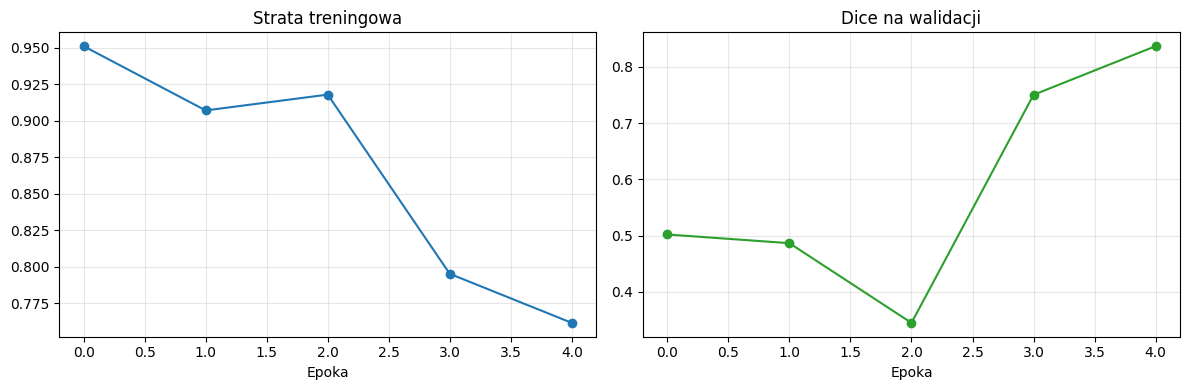

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([entry[0] for entry in history], marker="o")
axes[0].set_title("Strata treningowa")
axes[0].set_xlabel("Epoka")
axes[0].grid(alpha=0.3)
axes[1].plot([entry[1] for entry in history], marker="o", color="tab:green")
axes[1].set_title("Dice na walidacji")
axes[1].set_xlabel("Epoka")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Wynik na wybranym obrazie

Ładujemy najlepszy zapisany model i przewidujemy całą maskę. Próg `0.5` zamienia prawdopodobieństwo na decyzję binarną. Na wykresie pokazujemy zdjęcie, prawdopodobieństwo oraz finalną maskę.

Dice dla obrazu 0495dcf27283_06: 0.8761


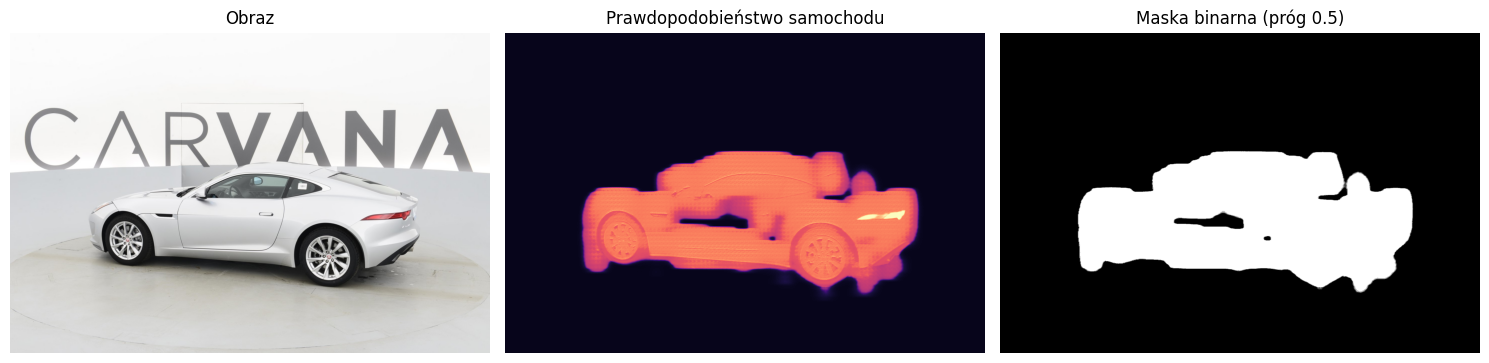

In [15]:
assert CHECKPOINT_PATH.exists(), f"Brak checkpointu w {CHECKPOINT_PATH} — uruchom komórkę treningową do końca"
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True))
sample_id = val_ids[0]
probability = predict_full_image(model, IMAGES_DIR / f"{sample_id}.jpg")
prediction = probability > 0.5
ground_truth = np.array(Image.open(MASKS_DIR / f"{sample_id}_mask.gif").convert("L")) > 0
print(f"Dice dla obrazu {sample_id}: {dice_score(torch.from_numpy(prediction), torch.from_numpy(ground_truth)):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(Image.open(IMAGES_DIR / f"{sample_id}.jpg").convert("RGB"))
axes[0].set_title("Obraz")
axes[1].imshow(probability, cmap="magma")
axes[1].set_title("Prawdopodobieństwo samochodu")
axes[2].imshow(prediction, cmap="gray")
axes[2].set_title("Maska binarna (próg 0.5)")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

### Test działania

Notebook został uruchomiony w trybie szybkim i przeszedł bez błędów:

| Ustawienie | Trening | Walidacja | Dice |
|---|---|---|---|
| 1 epoka | 8 obrazów | 2 obrazy | około 0,3 |

To smoke test, nie benchmark — dwa obrazy walidacyjne nie dają wiarygodnej oceny jakości. Log kształtów z tego uruchomienia:

```text
Batch obrazów: (1, 3, 572, 572)
Batch masek docelowych: (1, 388, 388)
Batch masek kontekstowych: (1, 572, 572)
Wyjście: (1, 2, 388, 388)
Parametry: 31 031 810
```

Dice po jednej epoce jest niski — to oczekiwane przy tak małej próbce. Pełny trening wymaga większej liczby danych i epok.

## Podsumowanie

Mamy kompletną, samowystarczalną implementację U-Net:

- architektura zgodna z artykułem: valid convolutions, 5 poziomów, skip connections, up-conv, 1×1 na wyjściu,
- trening z ważoną entropią krzyżową i mapą wag,
- predykcja dużych obrazów metodą overlap-tile,
- zapis i wczytanie najlepszego modelu.

Możliwe kierunki rozwoju:

- dodatkowa augmentacja: obroty i zmiany jasności,
- dłuższy trening na wszystkich 5088 obrazach,
- porównanie z wariantem z BatchNorm i bilinear upsampling (jak w `projekt/Pytorch-UNet`),
- metryki IoU i wizualizacja błędów na granicach.